# ANN for the SABR approximation: McGhee (2018) §5.1

Train the 14 → N (softplus) → 10 network on the Hagan β=1 dataset (T ∈ [1D, 1Y]) for N ∈ {250, 500, 750, 1000}, then check it against the error ranges the paper reports for Figures 2–6.

Training recipe (the paper's network, loss and optimizer; where the paper is silent we chose):
- one softplus hidden layer, softplus output, MSE on implied vol, Adam, batch 32 (Keras default)
- inputs min-max scaled to [0, 1] on the training set (stored in the model)
- learning rate 1e-3, halved after 100 epochs without a new best loss; stop after 500 epochs without one (≈ 11–15k epochs)

**Log inputs** (`LOG_INPUTS = True`, models `ann_log_{N}`): the network sees (√T, α, ν₁ₘ, ρ, ln K₁..K₁₀) instead of the raw inputs, min-max scaled the same way (`log_features` in `src/model.py`). Sections 3–5 compare them with the raw-input models `ann_{N}` (dashed).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

from src.hagan import DATA_DIR, COLUMNS_X, COLUMNS_Y, hagan_iv, make_strikes, check_against_paper
from src.model import SABRNet, train, smile

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)

## 1. Data
The Hagan dataset: 100k grid points and 150k random points for training, plus 50k random points for testing.

In [2]:
d = np.load(DATA_DIR / "hagan_1d_1y.npz")
X_train, y_train, X_test, y_test = d["X_train"], d["y_train"], d["X_test"], d["y_test"]
print({k: d[k].shape for k in ["X_train", "y_train", "X_test", "y_test"]})
pd.DataFrame(np.hstack((X_train, y_train)), columns=COLUMNS_X + COLUMNS_Y).describe().T.round(4)

{'X_train': (250000, 14), 'y_train': (250000, 10), 'X_test': (50000, 14), 'y_test': (50000, 10)}


,count,mean,std,min,25%,50%,75%,max
T,250000.0,0.5015,0.2890,0.0027,0.2519,0.5020,0.7505,1.0000
alpha,250000.0,0.2750,0.1355,0.0500,0.1500,0.2750,0.4000,0.5000
nu,250000.0,1.1342,1.3835,0.0144,0.4282,0.8744,1.3518,22.0605
rho,250000.0,-0.0006,0.5420,-0.9000,-0.5000,-0.0008,0.5000,0.9000
K1,250000.0,0.5281,0.2304,0.0291,0.3402,0.5270,0.7203,0.9946
K2,250000.0,0.5978,0.2177,0.0511,0.4294,0.6124,0.7807,0.9966
K3,250000.0,0.6823,0.2004,0.0898,0.5389,0.7145,0.8502,0.9987
K4,250000.0,0.7856,0.1822,0.1576,0.6683,0.8300,0.9349,1.0482
K5,250000.0,0.9134,0.1789,0.2768,0.8104,0.9415,1.0237,1.5400
K6,250000.0,1.0732,0.2251,0.4780,0.9461,1.0299,1.1640,2.3512


Sanity check of the labels: Hagan against paper Table 6. The paper rounds to 0.01%, so a max error of ±0.5 bp is the noise floor.

In [3]:
print(f"Max error vs. Table 6: {check_against_paper():.2f} bp")

Max error vs. Table 6: 0.53 bp


## 2. Training
The first cell trains all sizes in parallel (`src/train_ann.py`, one process per size) and redraws the loss every 10 s. Interrupting the cell stops training. `data/ann_{N}.pt` is a checkpoint saved every 10 epochs: rerunning continues from it up to `EPOCHS` (sizes already there, or auto-stopped, are skipped). Delete the file to retrain from scratch. Full training takes 1–2 days of CPU time per size.


In [4]:
SIZES = [250, 500, 750, 1000]
EPOCHS = 20000  # cap, counting epochs already in data/{PREFIX}_{N}.pt; runs normally auto-stop before it
LOG_INPUTS = True  # True: ann_log_{N}, (sqrt T, alpha, nu_1M, rho, ln K) features; False: ann_{N}, raw inputs
PREFIX = "ann_log" if LOG_INPUTS else "ann"

In [ ]:
import os, re, signal, subprocess, sys, time
from IPython.display import clear_output

def read_log(h):
    rows = re.findall(r"epoch\s+(\d+)/\d+\s+loss (\S+)\s+lr (\S+)", (DATA_DIR / f"{PREFIX}_{h}.log").read_text()) \
        if (DATA_DIR / f"{PREFIX}_{h}.log").exists() else []
    return np.array(rows, dtype=float).reshape(-1, 3)

def plot_progress(elapsed):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    for h in SIZES:
        r = read_log(h)
        if len(r):
            a1.semilogy(r[:, 0], r[:, 1], label=f"N={h}  ep {int(r[-1, 0])}  loss {r[-1, 1]:.2e}")
            a2.semilogy(r[:, 0], r[:, 2], label=f"N={h}")
    a1.set(xlabel="epoch", ylabel="train MSE (vol²)", title=f"Training loss ({elapsed / 60:.1f} min)")
    a2.set(xlabel="epoch", ylabel="learning rate", title="Learning rate")
    for a in (a1, a2):
        a.grid(alpha=0.3)
        if a.lines: a.legend(fontsize=8)
    plt.show()

proc = subprocess.Popen([sys.executable, "-m", "src.train_ann", *map(str, SIZES), "--epochs", str(EPOCHS),
                         *(["--log-inputs"] if LOG_INPUTS else [])],
                        start_new_session=True)  # own process group, so an interrupt can stop all workers
t0 = time.time()
try:
    while proc.poll() is None:
        clear_output(wait=True); plot_progress(time.time() - t0)
        time.sleep(10)
except KeyboardInterrupt:
    os.killpg(proc.pid, signal.SIGTERM)
    print("training stopped")
clear_output(wait=True); plot_progress(time.time() - t0)
print("exit code", proc.wait())

--- N=250 ---
20000 epochs, final train MSE 5.441e-08
--- N=500 ---
19817 epochs, final train MSE 4.388e-08
--- N=750 ---


20000 epochs, final train MSE 4.741e-08
--- N=1000 ---
15265 epochs, final train MSE 5.744e-08


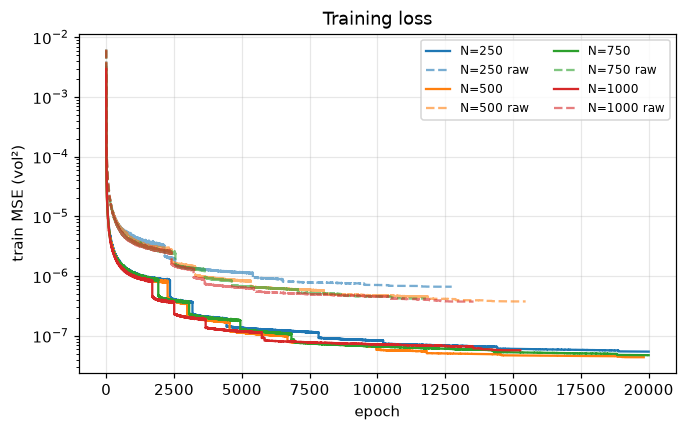

In [5]:
nets, losses = {}, {}
for h in SIZES:
    path = DATA_DIR / f"{PREFIX}_{h}.pt"
    net = SABRNet(h, log_inputs=LOG_INPUTS)
    print(f"--- N={h} ---")
    if path.exists():
        ckpt = torch.load(path)
        net.load_state_dict(ckpt["state"])
        losses[h] = ckpt["losses"]
        done = ckpt.get("stopped", True) or len(losses[h]) >= EPOCHS
    else:  # same recipe as the cell above, in-process
        net.set_input_range(X_train)
        losses[h] = train(net, X_train, y_train, epochs=EPOCHS, log_every=1)
        torch.save({"state": net.state_dict(), "losses": losses[h]}, path)
        done = True
    print(f"{len(losses[h])} epochs{'' if done else ' (STILL TRAINING: latest checkpoint)'}, final train MSE {losses[h][-1]:.3e}")
    nets[h] = net.eval()

# raw-input models for comparison (dashed in the plots below)
ref_nets, ref_losses = {}, {}
for h in SIZES if LOG_INPUTS else []:
    if (path := DATA_DIR / f"ann_{h}.pt").exists():
        ckpt = torch.load(path)
        ref_nets[h] = SABRNet(h)
        ref_nets[h].load_state_dict(ckpt["state"])
        ref_nets[h].eval()
        ref_losses[h] = ckpt["losses"]

fig, ax = plt.subplots(figsize=(7, 4))
for h in SIZES:
    line, = ax.semilogy(losses[h], label=f"N={h}")
    if h in ref_losses:
        ax.semilogy(ref_losses[h], "--", color=line.get_color(), alpha=0.6, label=f"N={h} raw")
ax.set(xlabel="epoch", ylabel="train MSE (vol²)", title="Training loss")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)

## 3. Out-of-sample error on the 50k test set
Errors are in implied-vol basis points (1 bp = 0.01%). The paper reports no aggregate test metric, so these numbers are our own baseline. With `LOG_INPUTS`, each metric shows the log-input model next to the raw-input one.

In [6]:
def metrics(e):
    return {"MAE (bp)": np.abs(e).mean(), "RMSE (bp)": np.sqrt((e**2).mean()),
            "p99 |err| (bp)": np.percentile(np.abs(e), 99), "max |err| (bp)": np.abs(e).max()}

TAG = "log" if LOG_INPUTS else "raw"
err = {h: (nets[h].predict(X_test) - y_test) * 1e4 for h in SIZES}
ref_err = {h: (ref_nets[h].predict(X_test) - y_test) * 1e4 for h in ref_nets}
rows = {(TAG, h): metrics(e) for h, e in err.items()} | {("raw", h): metrics(e) for h, e in ref_err.items()}
pd.DataFrame(rows).T.rename_axis(["inputs", "N"]).unstack("inputs").round(3)

MAE (bp)        RMSE (bp)        p99 |err| (bp)         max |err| (bp)  \
inputs      log    raw       log    raw            log     raw            log   
N                                                                               
250       1.322  4.718     2.137  7.039          8.291  25.063         40.415   
500       1.158  3.599     1.899  5.392          7.448  18.991         41.904   
750       1.195  3.777     1.938  5.632          7.611  20.073         38.706   
1000      1.289  3.550     2.179  5.265          8.700  18.479         53.164   

                 
inputs      raw  
N                
250     153.195  
500     133.111  
750     130.306  
1000    131.003

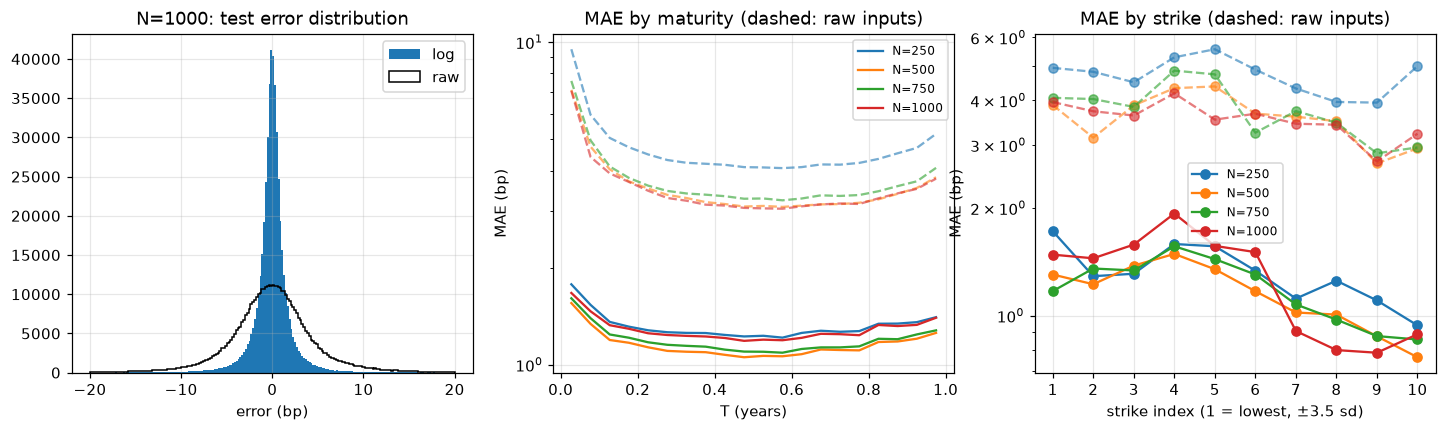

In [7]:
H = max(SIZES)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(err[H].ravel(), bins=200, range=(-20, 20), label=TAG)
if H in ref_err:
    axes[0].hist(ref_err[H].ravel(), bins=200, range=(-20, 20), histtype="step", color="k", label="raw")
axes[0].set(xlabel="error (bp)", title=f"N={H}: test error distribution"); axes[0].legend()
T_test = X_test[:, 0]
bins = np.linspace(T_test.min(), T_test.max(), 21)
idx = np.digitize(T_test, bins)
mae_T = lambda e: [np.abs(e[idx == i]).mean() for i in range(1, len(bins))]
for h in SIZES:
    line, = axes[1].plot((bins[:-1] + bins[1:]) / 2, mae_T(err[h]), label=f"N={h}")
    axes[2].plot(range(1, 11), np.abs(err[h]).mean(0), "o-", color=line.get_color(), label=f"N={h}")
    if h in ref_err:
        axes[1].plot((bins[:-1] + bins[1:]) / 2, mae_T(ref_err[h]), "--", color=line.get_color(), alpha=0.6)
        axes[2].plot(range(1, 11), np.abs(ref_err[h]).mean(0), "o--", color=line.get_color(), alpha=0.6)
axes[1].set(xlabel="T (years)", ylabel="MAE (bp)", title="MAE by maturity (dashed: raw inputs)", yscale="log")
axes[2].set(xlabel="strike index (1 = lowest, ±3.5 sd)", ylabel="MAE (bp)", title="MAE by strike (dashed: raw inputs)",
            yscale="log", xticks=range(1, 11))
for a in axes[1:]: a.legend(fontsize=8)
for a in axes: a.grid(alpha=0.3)

## 4. Paper Figures 2–4: smiles from all four networks
Both the Hagan reference and the ANN outputs are taken at the 10 strikes and passed through a cubic spline (§4.3), so the error below is the network error alone, evaluated on a fine strike grid. Units: vol %. Dashed: the largest raw-input network, for comparison.

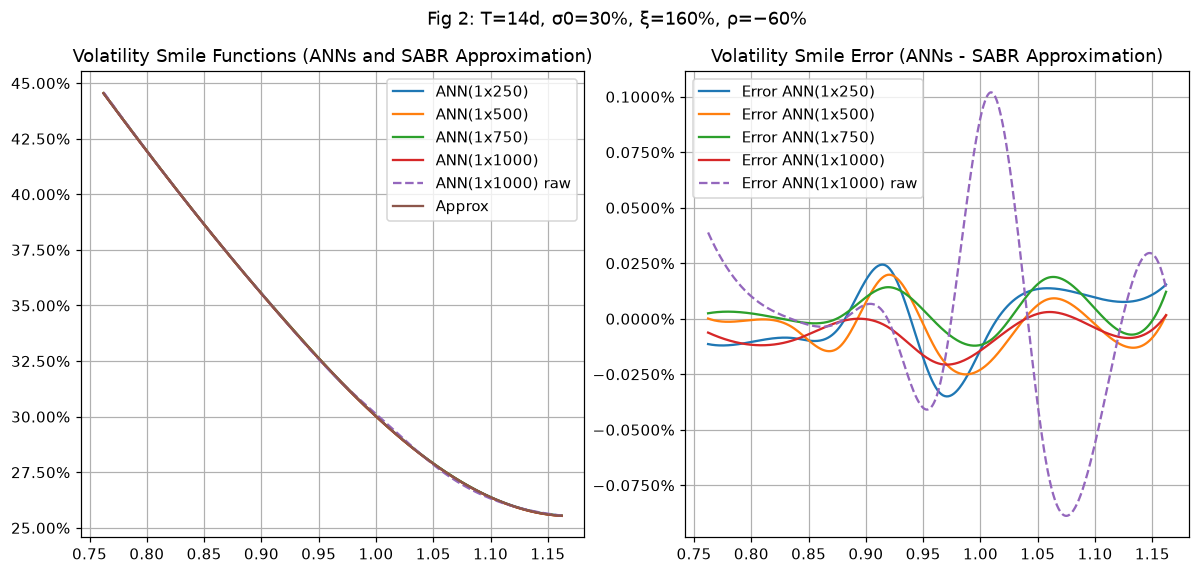

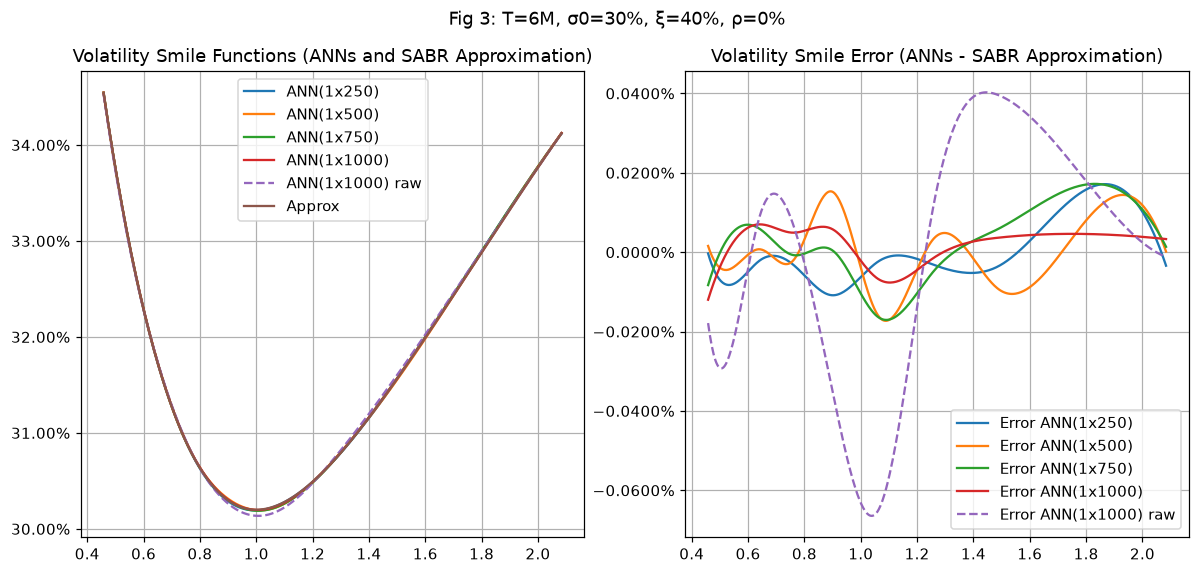

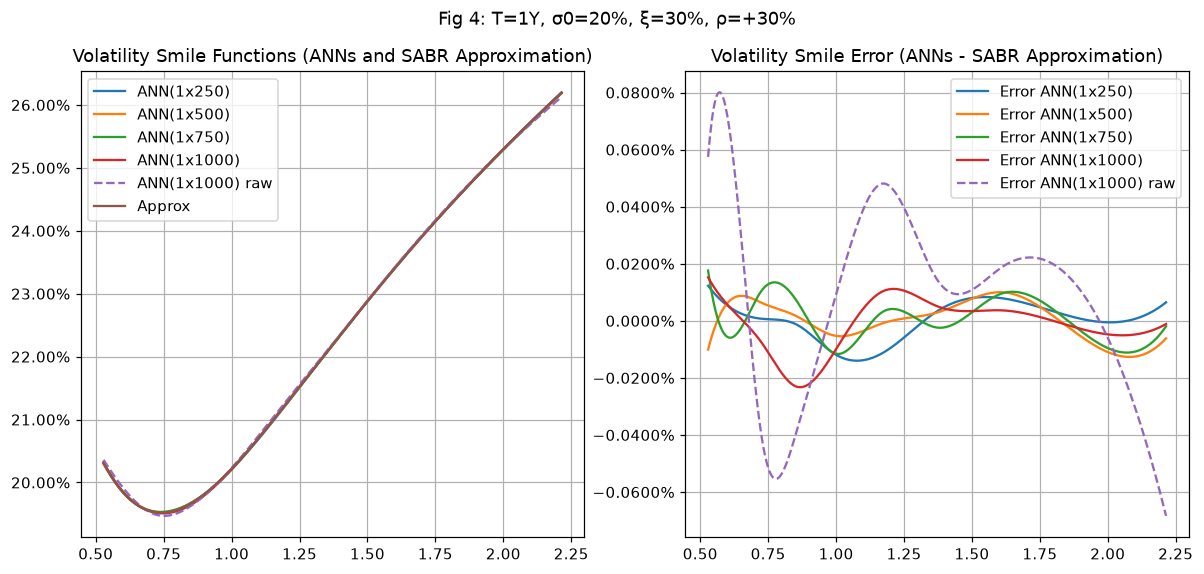

,figure,inputs,N,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 2,log,250,-0.0350,0.0244,-0.030,0.10,False
1,Fig 2,log,500,-0.0250,0.0198,-0.030,0.10,True
2,Fig 2,log,750,-0.0121,0.0188,-0.030,0.10,True
3,Fig 2,log,1000,-0.0207,0.0030,-0.030,0.10,True
4,Fig 2,raw,1000,-0.0888,0.1020,-0.030,0.10,False
5,Fig 3,log,250,-0.0109,0.0171,-0.015,0.02,True
6,Fig 3,log,500,-0.0173,0.0153,-0.015,0.02,False
7,Fig 3,log,750,-0.0171,0.0172,-0.015,0.02,False
8,Fig 3,log,1000,-0.0120,0.0070,-0.015,0.02,True
9,Fig 3,raw,1000,-0.0664,0.0403,-0.015,0.02,False


In [8]:
from matplotlib.ticker import PercentFormatter

def smiles(T, a, nu, rho, net, n=500):
    K = make_strikes(1.0, T, a, rho, nu)
    Kf = np.linspace(K[0], K[-1], n)
    ref = smile(K, hagan_iv(1.0, K, T, a, 1.0, rho, nu))(Kf)
    ann = smile(K, net.predict(np.r_[T, a, nu, rho, K][None])[0])(Kf)
    return Kf, ref, ann

def paper_plot(K, ref, curves, what, decimals=(2, 4), suptitle=""):
    """Paper layout: functions on the left, ANN − Approx error on the right, y-axes in %."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))
    for name, c in curves.items():
        ls = "--" if "raw" in name else "-"
        left.plot(K, c, ls, label=name)
        right.plot(K, c - ref, ls, label=f"Error {name}")
    left.plot(K, ref, label="Approx")
    left.set_title(f"{what} Functions (ANNs and SABR Approximation)")
    right.set_title(f"{what} Error (ANNs - SABR Approximation)")
    for ax, dec in zip((left, right), decimals):
        ax.yaxis.set_major_formatter(PercentFormatter(1, dec))
        ax.grid(); ax.legend()
    fig.suptitle(suptitle)
    plt.show()

FIGS = {  # name: (T, sigma0, xi, rho), paper error range in vol %
    "Fig 2: T=14d, σ0=30%, ξ=160%, ρ=−60%": ((14 / 365, 0.30, 1.60, -0.60), (-0.03, 0.10)),
    "Fig 3: T=6M, σ0=30%, ξ=40%, ρ=0%":     ((0.5, 0.30, 0.40, 0.00), (-0.015, 0.02)),
    "Fig 4: T=1Y, σ0=20%, ξ=30%, ρ=+30%":   ((1.0, 0.20, 0.30, 0.30), (-0.025, 0.02)),
}
rows = []
for name, (p, paper) in FIGS.items():
    curves = {}
    for h, net, tag in [(h, nets[h], TAG) for h in SIZES] + [(H, ref_nets[H], "raw")] * (H in ref_nets):
        Kf, ref, ann = smiles(*p, net)
        curves[f"ANN(1x{h})" + (" raw" if tag == "raw" and LOG_INPUTS else "")] = ann
        e = (ann - ref) * 100
        rows.append({"figure": name[:5], "inputs": tag, "N": h, "ours min (%)": e.min(), "ours max (%)": e.max(),
                     "paper min (%)": paper[0], "paper max (%)": paper[1],
                     "within paper range": paper[0] <= e.min() and e.max() <= paper[1]})
    paper_plot(Kf, ref, curves, "Volatility Smile", suptitle=name)
pd.DataFrame(rows).round(4)

## 5. Paper Figures 5–6: smile, CDF and PDF (largest trained N)
Black prices with F=1 and no discounting: CDF(K) = 1 + ∂C/∂K and PDF(K) = ∂²C/∂K², both by finite differences on the spline smile. Units are % (probability × 100, density × 100), as in the paper. Dashed: the raw-input network of the same size.

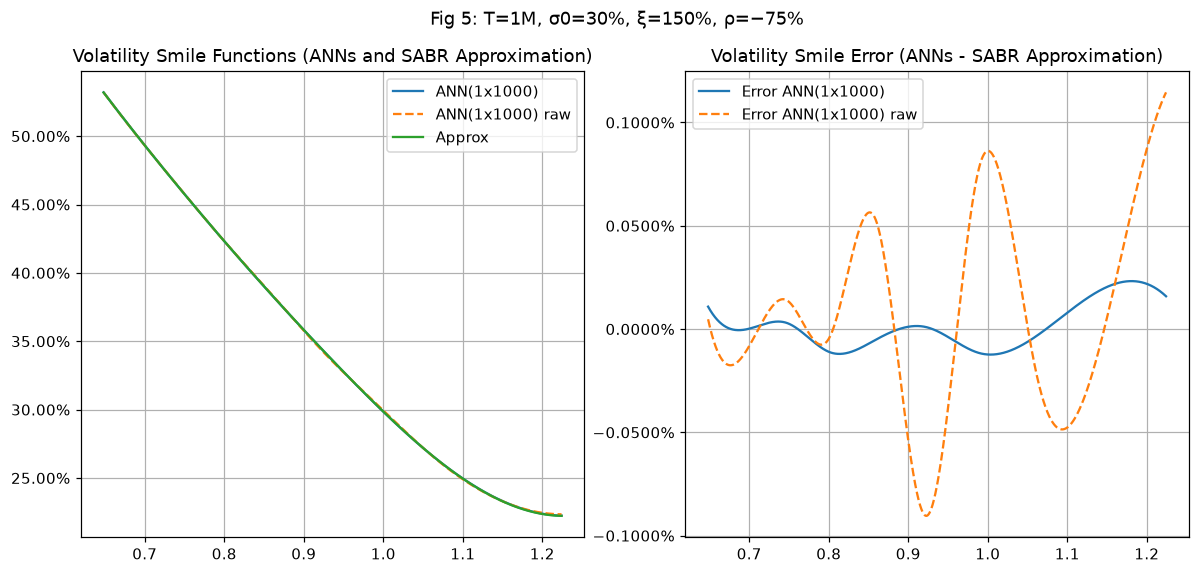

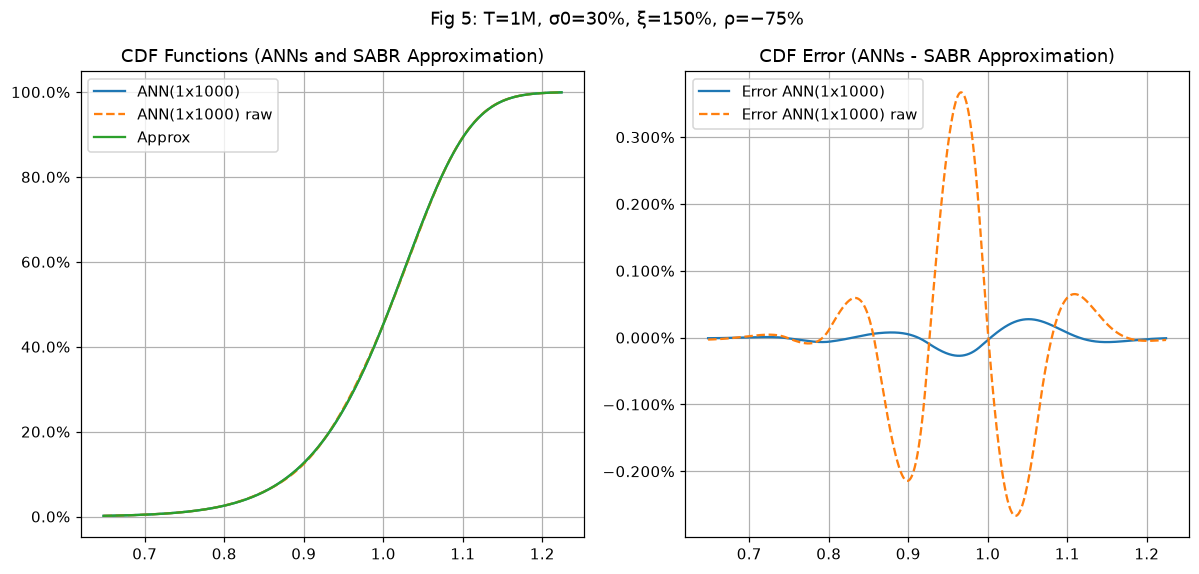

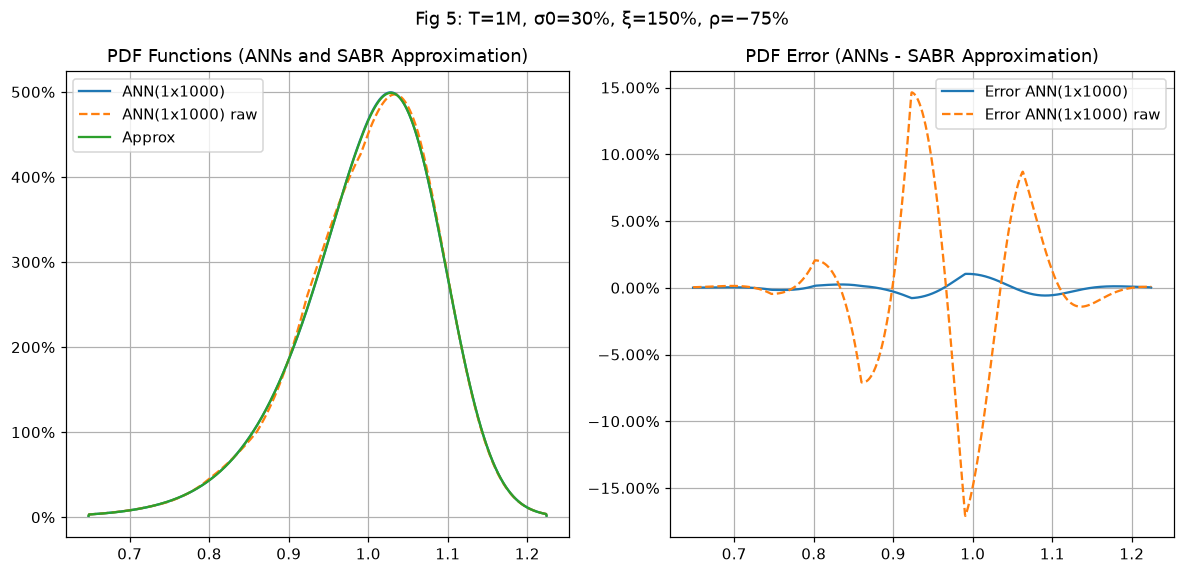

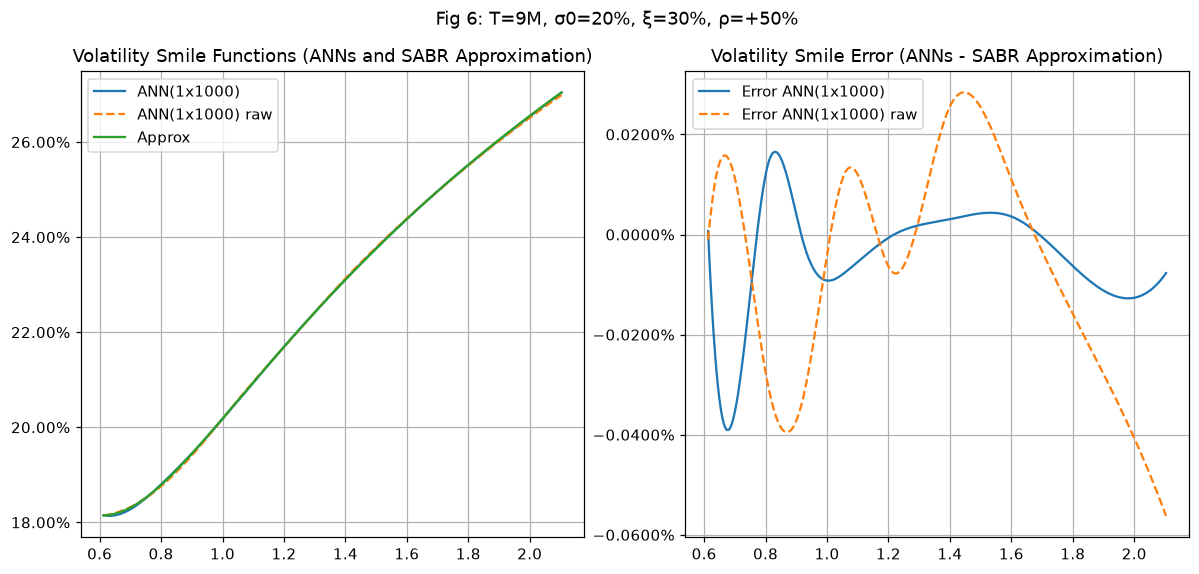

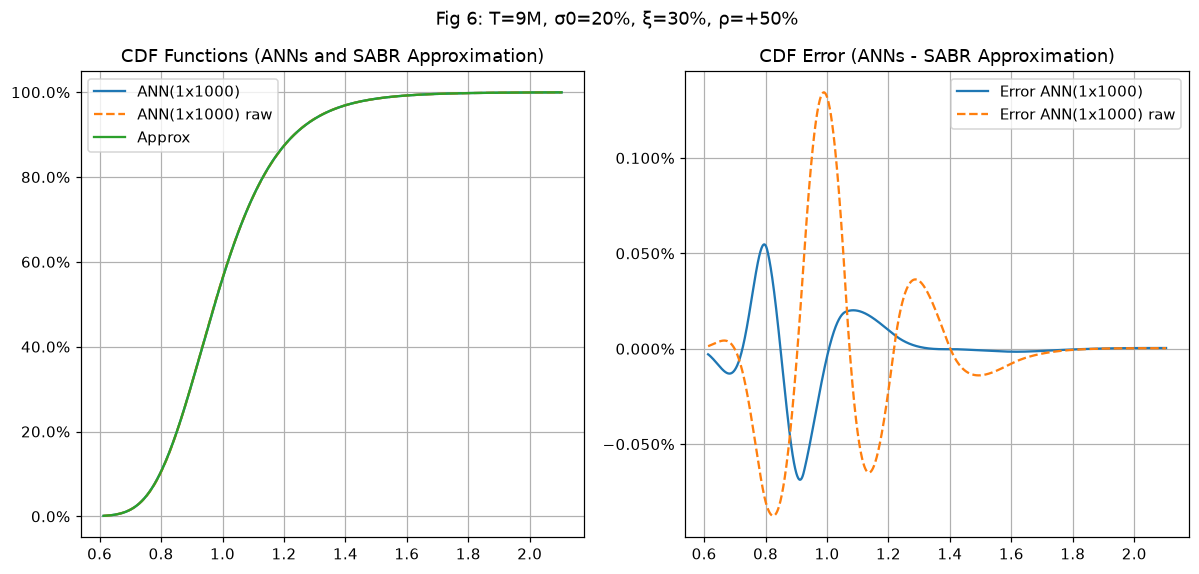

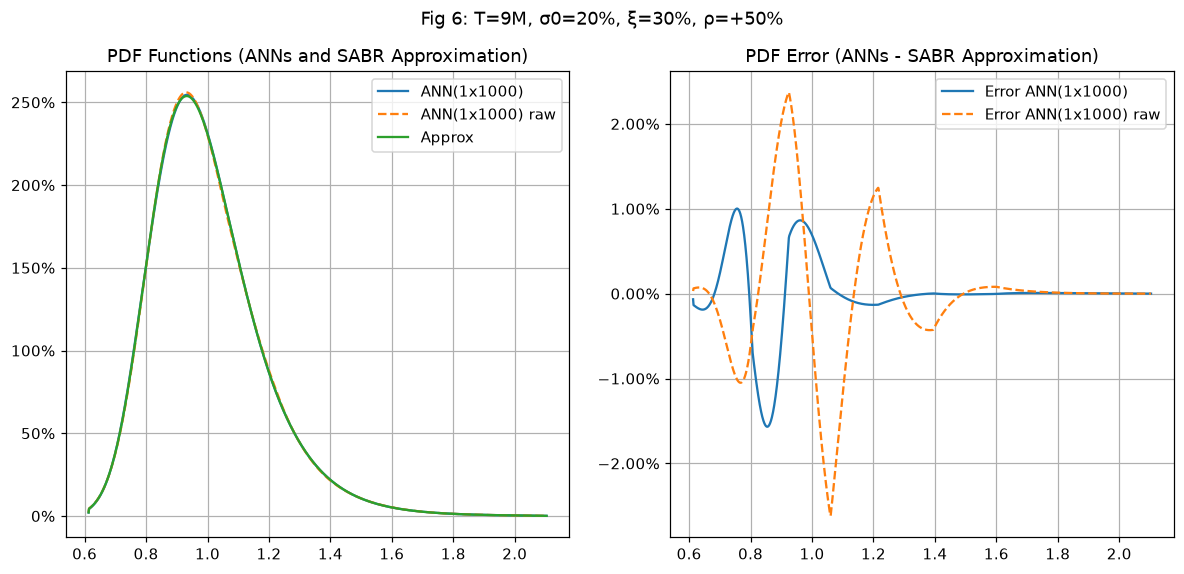

,figure,quantity,inputs,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 5,Volatility Smile,log,-0.0124,0.0232,-0.0300,0.020,False
1,Fig 5,Volatility Smile,raw,-0.0904,0.1146,-0.0300,0.020,False
2,Fig 5,CDF,log,-0.0272,0.0276,-0.0600,0.040,True
3,Fig 5,CDF,raw,-0.2667,0.3671,-0.0600,0.040,False
4,Fig 5,PDF,log,-0.7745,1.0410,-2.0000,2.000,True
5,Fig 5,PDF,raw,-17.0877,14.6390,-2.0000,2.000,False
6,Fig 6,Volatility Smile,log,-0.0391,0.0165,-0.0025,0.015,False
7,Fig 6,Volatility Smile,raw,-0.0562,0.0284,-0.0025,0.015,False
8,Fig 6,CDF,log,-0.0687,0.0547,-0.0200,0.030,False
9,Fig 6,CDF,raw,-0.0876,0.1344,-0.0200,0.030,False


In [9]:
def black_call(K, sig, T):
    s = sig * np.sqrt(T)
    d1 = (-np.log(K) + s**2 / 2) / s
    return norm.cdf(d1) - K * norm.cdf(d1 - s)

def cdf_pdf(K, sig, T):
    dC = np.gradient(black_call(K, sig, T), K)
    return 1 + dC, np.gradient(dC, K)

FIGS2 = {  # paper: smile range, CDF range, max |PDF error|  (all in %)
    "Fig 5: T=1M, σ0=30%, ξ=150%, ρ=−75%": ((1 / 12, 0.30, 1.50, -0.75), (-0.03, 0.02), (-0.06, 0.04), 2.0),
    "Fig 6: T=9M, σ0=20%, ξ=30%, ρ=+50%":  ((0.75, 0.20, 0.30, 0.50), (-0.0025, 0.015), (-0.02, 0.03), 0.4),
}
rows = []
models = {TAG: nets[H]} | ({"raw": ref_nets[H]} if H in ref_nets else {})
for name, (p, s_rng, c_rng, pdf_max) in FIGS2.items():
    T = p[0]
    out = {tag: smiles(*p, net, n=2000) for tag, net in models.items()}
    Kf, ref, _ = out[TAG]
    cr, pr = cdf_pdf(Kf, ref, T)
    anns = {tag: (a, *cdf_pdf(Kf, a, T)) for tag, (_, _, a) in out.items()}
    for j, (what, r, rng, dec) in enumerate([("Volatility Smile", ref, s_rng, (2, 4)),
                                             ("CDF", cr, c_rng, (1, 3)),
                                             ("PDF", pr, (-pdf_max, pdf_max), (0, 2))]):
        curves = {f"ANN(1x{H})" + (" raw" if tag == "raw" and LOG_INPUTS else ""): v[j] for tag, v in anns.items()}
        paper_plot(Kf, r, curves, what, dec, suptitle=name)
        for tag, v in anns.items():
            e = (v[j] - r) * 100
            rows.append({"figure": name[:5], "quantity": what, "inputs": tag, "ours min (%)": e.min(), "ours max (%)": e.max(),
                         "paper min (%)": rng[0], "paper max (%)": rng[1],
                         "within paper range": rng[0] <= e.min() and e.max() <= rng[1]})
pd.DataFrame(rows).round(4)

## 6. Summary

In [10]:
print(f"Hagan labels vs. Table 6: {check_against_paper():.2f} bp (≈ the paper's rounding)")
print(f"Test-set MAE, N={H}: {np.abs(err[H]).mean():.3f} bp ({TAG} inputs)"
      + (f", {np.abs(ref_err[H]).mean():.3f} bp (raw inputs)" if H in ref_err else ""))
print("Figures 2–6: see the 'within paper range' columns above.")

Hagan labels vs. Table 6: 0.53 bp (≈ the paper's rounding)
Test-set MAE, N=1000: 1.289 bp (log inputs), 3.550 bp (raw inputs)
Figures 2–6: see the 'within paper range' columns above.
